# SPY: LSTM and GARCH–LSTM baseline
**DSAN 6600 · Check-in 2**

A sequential forecasting pipeline: load data → inspect returns → rolling GARCH estimates → sliding windows → PyTorch LSTM → held-out metrics → prediction plots.

The notebook uses step-by-step pandas operations, a small `nn.LSTM` with a linear head, MSE/Adam training, and observed/predicted closing-price plots. Training-only scaling and explicit timestamps keep preprocessing and label alignment consistent with the chronological evaluation.

The task follows Check-in 1: at the close of a completed bar, predict the **next within-session 15-minute log return**, then reconstruct its close. This is a baseline, with no architecture search, attention, trading simulation, or test-based tuning. Negative results are retained.

**Run:** Python 3.12; install `requirements-baseline.txt` in a separate virtual environment, select that environment as the kernel, then Run All. The notebook works from the repository root or `scripts/`. It never downloads prices. All data/checkpoints/tables go to `data/`; all PNG figures go to `visualizations/`.

In [1]:
from pathlib import Path
import os
import sys
import json
import time
import copy
import random
import hashlib
import platform
import warnings
from importlib import metadata

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas_market_calendars as mcal
from IPython.display import display, Image, Markdown
from arch import arch_model
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})
torch.set_num_threads(4)
# CPU keeps the three-seed comparison repeatable across local runs.
DEVICE = torch.device("cpu")
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent]
            if (p / "scripts" / "fetch_spy.py").exists())
DATA = ROOT / "data"
FIGURES = ROOT / "visualizations"
for folder in [DATA, DATA / "intermediate", DATA / "results", DATA / "models", FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

CONFIG = {"lookback": 26, "garch_sessions": 100,
          "hidden_dim": 32, "num_layers": 2, "dropout": 0.1,
          "batch_size": 256, "learning_rate": 0.001,
          "max_epochs": 20, "patience": 4,
          "seeds": [42, 123, 2026], "device": str(DEVICE),
          "train_end": "2022-12-31", "validation_end": "2024-12-31"}
(DATA / "results" / "config.json").write_text(json.dumps(CONFIG, indent=2))

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(FIGURES / name)))

print("Project:", ROOT)
print("Python:", platform.python_version(), "PyTorch:", torch.__version__)
display(pd.Series(CONFIG, name="setting").to_frame())

Project: /Users/yinhengyuan/Documents/ggt/DSAN/6600/6600-project
Python: 3.12.14 PyTorch: 2.15.0


,setting
lookback,26
garch_sessions,100
hidden_dim,32
num_layers,2
dropout,0.1
batch_size,256
learning_rate,0.001
max_epochs,20
patience,4
seeds,"[42, 123, 2026]"


## 1. Load the snapshot and retain regular-session bars

The snapshot contains premarket and postmarket observations. Use the NYSE calendar as a US-equity core-session proxy, including holidays and early closes. A timestamp denotes a bar's **start**; it becomes available 15 minutes later. Do not fill the missing bar or treat overnight changes as 15-minute returns.

In [2]:
filename = "spy_15min_2016_2026.parquet"
source = DATA / filename
if not source.exists():
    # Compatibility with the original repository layout.
    legacy = ROOT / filename
    if not legacy.exists():
        raise FileNotFoundError("Place the supplied snapshot in data/" + filename)
    import shutil
    shutil.copy2(legacy, source)

raw = pd.read_parquet(source)
source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
raw["ts_utc"] = pd.to_datetime(raw["ts_utc"], utc=True)
raw["ts_et"] = raw.ts_utc.dt.tz_convert("America/New_York")
assert not raw.ts_utc.duplicated().any()
assert np.isfinite(raw[["open", "high", "low", "close", "volume"]].to_numpy()).all()
assert (raw[["open", "high", "low", "close"]] > 0).all().all()
assert (raw.volume >= 0).all()
assert ((raw.low <= raw[["open", "close"]].min(axis=1)) &
        (raw.high >= raw[["open", "close"]].max(axis=1))).all()
raw = raw.sort_values("ts_utc").reset_index(drop=True)

schedule = mcal.get_calendar("NYSE").schedule(
    start_date=raw.ts_et.min().date(), end_date=raw.ts_et.max().date())
expected = pd.DatetimeIndex([stamp for row in schedule.itertuples()
    for stamp in pd.date_range(row.market_open, row.market_close, freq="15min", inclusive="left")])
missing = expected.difference(pd.DatetimeIndex(raw.ts_utc))
spy = raw[raw.ts_utc.isin(expected)].copy().reset_index(drop=True)
spy["session"] = spy.ts_et.dt.strftime("%Y-%m-%d")
spy["year"] = spy.ts_et.dt.year
spy.to_parquet(DATA / "intermediate" / "spy_regular_sessions.parquet", index=False)
pd.DataFrame({"ts_utc": missing}).to_csv(DATA / "intermediate" / "missing_bars.csv", index=False)
audit = {"raw_rows": len(raw), "regular_rows": len(spy),
         "excluded_rows": len(raw) - len(spy), "sessions": spy.session.nunique(),
         "missing_regular_bars": len(missing), "sha256": source_hash,
         "first_ET": str(spy.ts_et.min()), "last_ET": str(spy.ts_et.max()),
         "feed": "unverified; downloader defaults to sip",
         "adjustment": "unverified; downloader defaults to all"}
(DATA / "results" / "data_manifest.json").write_text(json.dumps(audit, indent=2))
display(pd.Series(audit).to_frame("value"))
display(spy.head())

,value
raw_rows,169241
regular_rows,69973
excluded_rows,99268
sessions,2701
missing_regular_bars,1
sha256,bda19e9f8a784ee50d20fe7dc50826d5fce0fddea97b20...
first_ET,2016-01-04 09:30:00-05:00
last_ET,2026-09-30 15:45:00-04:00
feed,unverified; downloader defaults to sip
adjustment,unverified; downloader defaults to all


,ts_utc,ts_et,open,high,low,close,volume,trade_count,vwap,session,year
0,2016-01-04 14:30:00+00:00,2016-01-04 09:30:00-05:00,170.23,170.26,169.51,169.61,14712864.0,49916.0,169.972960,2016-01-04,2016
1,2016-01-04 14:45:00+00:00,2016-01-04 09:45:00-05:00,169.62,170.22,169.46,170.00,10981609.0,35420.0,169.891030,2016-01-04,2016
2,2016-01-04 15:00:00+00:00,2016-01-04 10:00:00-05:00,170.00,170.00,169.30,169.79,13964267.0,46705.0,169.555609,2016-01-04,2016
3,2016-01-04 15:15:00+00:00,2016-01-04 10:15:00-05:00,169.80,170.08,169.65,169.68,6823627.0,24815.0,169.840573,2016-01-04,2016
4,2016-01-04 15:30:00+00:00,2016-01-04 10:30:00-05:00,169.68,169.68,169.17,169.59,6984021.0,26630.0,169.448512,2016-01-04,2016


## 2. Returns, causal OHLCV features, and explicit labels

Calculate first differences of log prices. The target below occurs strictly after the final input bar. Sequence histories may cross earlier sessions; boundary and missing-interval indicators identify these transitions.

Returns are in natural-log units when saved. Features use basis points (1 bp = 0.0001 log-return units) where convenient. Training labels are standardized later; reported metrics are always converted back to return units or basis points.

In [3]:
step = pd.Timedelta(minutes=15)
previous_ok = (spy.session == spy.session.shift(1)) & (spy.ts_utc.diff() == step)
next_ok = (spy.session == spy.session.shift(-1)) & ((spy.ts_utc.shift(-1) - spy.ts_utc) == step)
spy["return"] = np.log(spy.close / spy.close.shift(1)).where(previous_ok)
spy["target_return"] = np.log(spy.close.shift(-1) / spy.close).where(next_ok)
spy["target_ts_utc"] = spy.ts_utc.shift(-1).where(next_ok)
spy["origin_available_utc"] = spy.ts_utc + step
spy["target_available_utc"] = spy.target_ts_utc + step
spy["target_close"] = spy.close.shift(-1).where(next_ok)
spy["split"] = np.select(
    [spy.target_ts_utc.dt.year <= 2022, spy.target_ts_utc.dt.year <= 2024, next_ok],
    ["train", "validation", "test"], default="excluded")

spy["return_bps"] = spy["return"].fillna(0) * 10000
spy["range_bps"] = (spy.high - spy.low) / spy.close * 10000
spy["close_open_bps"] = np.log(spy.close / spy.open) * 10000
spy["log_volume"] = np.log1p(spy.volume)
spy["volume_change"] = spy.log_volume.diff().where(previous_ok, 0)
spy["trailing_vol_bps"] = spy["return"].rolling(26, min_periods=10).std().fillna(0) * 10000
minute = spy.ts_et.dt.hour * 60 + spy.ts_et.dt.minute - (9 * 60 + 30)
spy["time_sin"] = np.sin(2 * np.pi * minute / 390)
spy["time_cos"] = np.cos(2 * np.pi * minute / 390)
spy["session_start"] = (spy.session != spy.session.shift(1)).astype(float)
spy["gap_or_boundary"] = (~previous_ok).astype(float)
market_features = ["return_bps", "range_bps", "close_open_bps", "log_volume", "volume_change",
                   "trailing_vol_bps", "time_sin", "time_cos", "session_start", "gap_or_boundary"]

# A direct timestamp check is easier to audit than shifted array positions.
valid_target = spy.target_return.notna()
assert (spy.loc[valid_target, "target_ts_utc"] == spy.loc[valid_target, "origin_available_utc"]).all()
assert (spy.loc[valid_target, "target_available_utc"] > spy.loc[valid_target, "origin_available_utc"]).all()
spy.to_parquet(DATA / "intermediate" / "spy_market_features.parquet", index=False)
display(spy.groupby("split").target_return.agg(["count", "mean", "std"]))
display(spy[["ts_et", "return", "target_return"]].head(5))

,count,mean,std
split,,,
excluded,0,NaN,NaN
test,10889,0.000009,0.001641
train,43893,0.000005,0.001687
validation,12490,0.000013,0.001220


,ts_et,return,target_return
0,2016-01-04 09:30:00-05:00,NaN,0.002297
1,2016-01-04 09:45:00-05:00,0.002297,-0.001236
2,2016-01-04 10:00:00-05:00,-0.001236,-0.000648
3,2016-01-04 10:15:00-05:00,-0.000648,-0.000531
4,2016-01-04 10:30:00-05:00,-0.000531,-0.003012


## 3. Training-period diagnostics and visualization

These diagnostics describe the training returns, not test-set outcomes. ADF and ARCH-LM use the chronological sequence of valid within-session returns, with overnight intervals removed. Concatenating sessions is an approximation to trading-bar time; lag calculations here are not a claim of continuous clock-time dynamics.

/var/folders/w0/d3tspk252t73_pvzt2sxb_sc0000gn/T/ipykernel_80877/490096171.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(train_returns, maxlag=26, autolag="AIC")
/private/tmp/6600-baseline-venv/lib/python3.12/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,test,statistic,p_value,lags
0,ADF on training returns,-42.996891,0.0,26
1,ARCH-LM on training returns,6379.424166,0.0,10


,training_return
count,43893.000000
mean,0.000005
std,0.001687
min,-0.027862
1%,-0.004880
50%,0.000045
99%,0.004585
max,0.038064


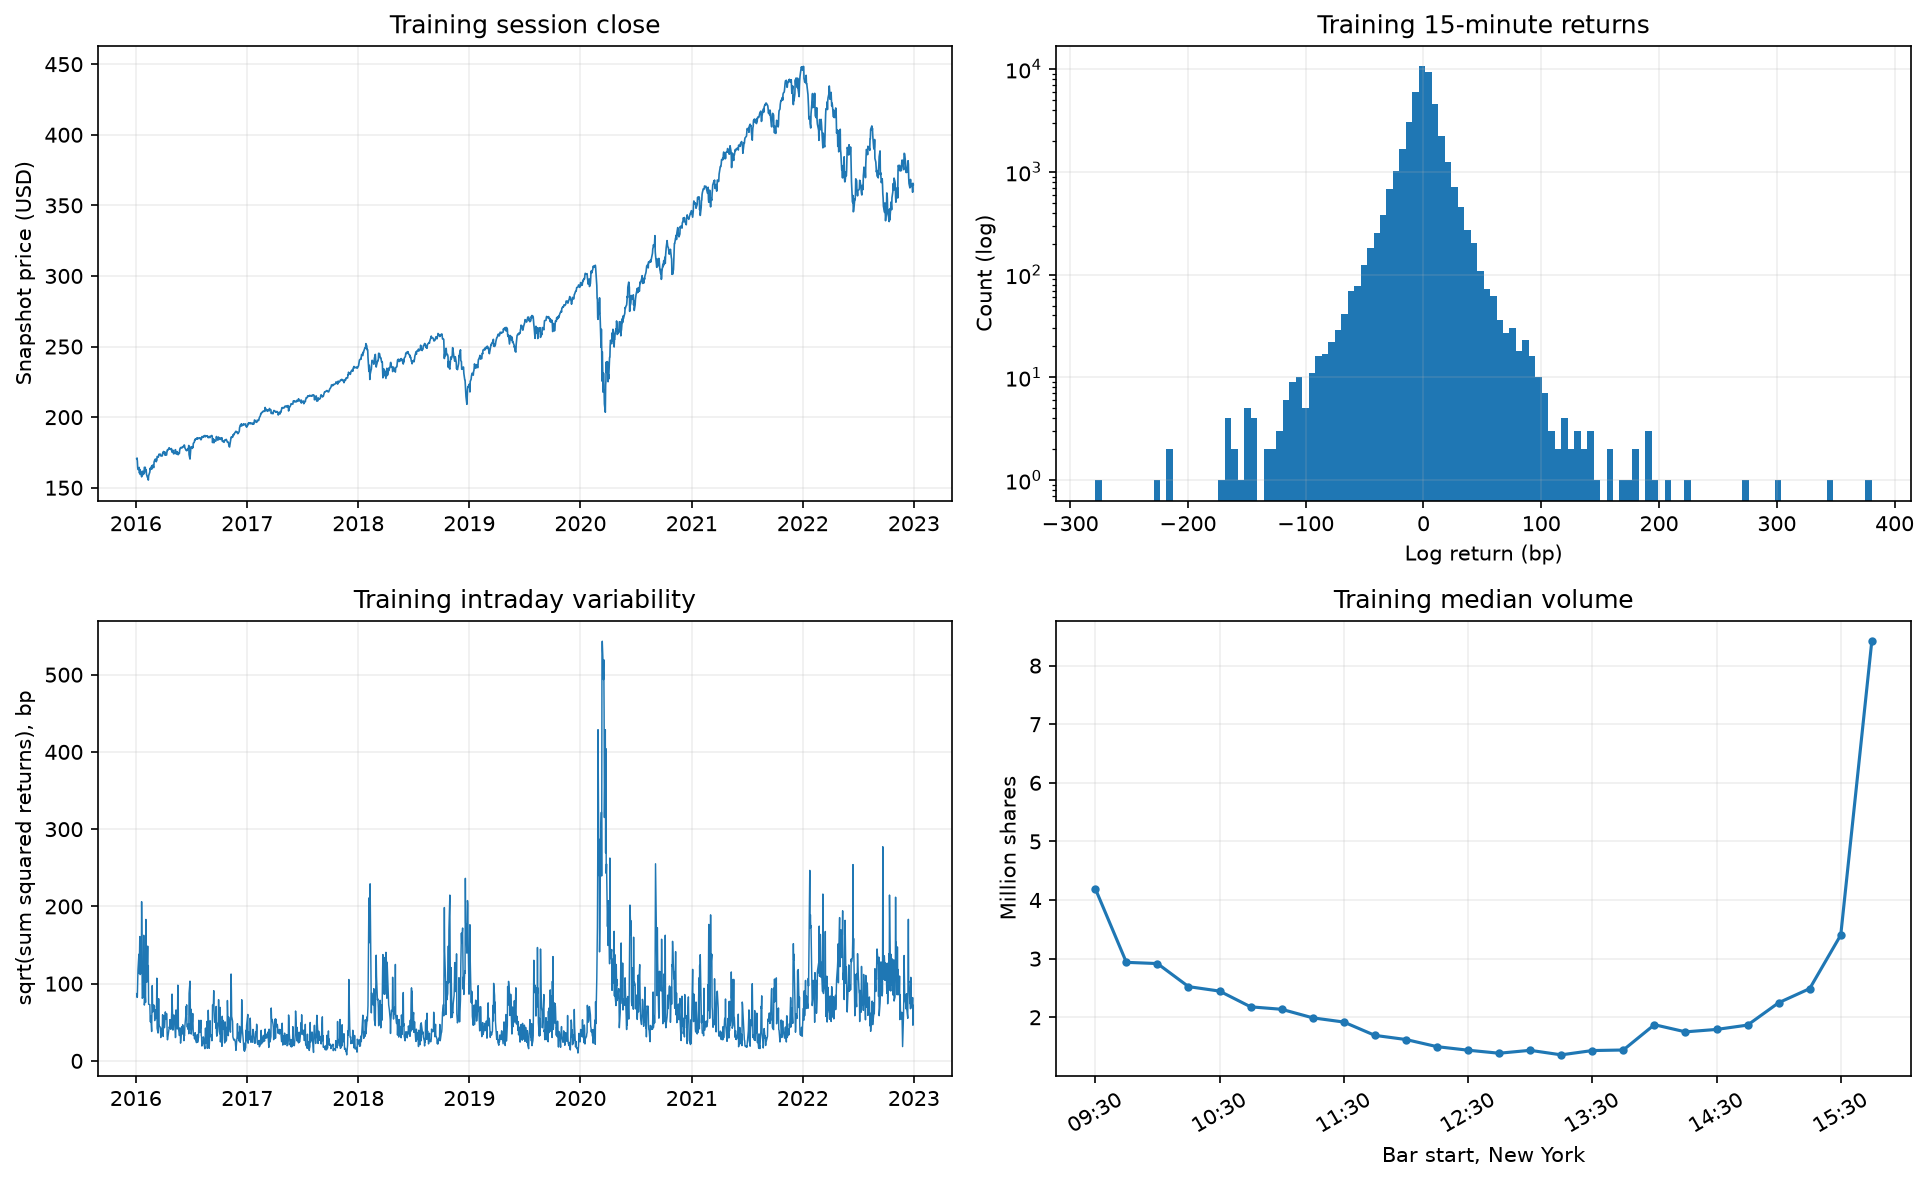

In [4]:
train_returns = spy.loc[spy.year <= 2022, "return"].dropna()
adf = adfuller(train_returns, maxlag=26, autolag="AIC")
arch_lm = het_arch(train_returns * 100, nlags=10)
diagnostics = pd.DataFrame([
    {"test": "ADF on training returns", "statistic": adf[0], "p_value": adf[1], "lags": adf[2]},
    {"test": "ARCH-LM on training returns", "statistic": arch_lm[0], "p_value": arch_lm[1], "lags": 10}
])
diagnostics.to_csv(DATA / "results" / "training_diagnostics.csv", index=False)
display(diagnostics)
display(train_returns.describe(percentiles=[0.01, 0.5, 0.99]).to_frame("training_return"))

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
train_spy = spy[spy.year <= 2022]
daily = train_spy.groupby("session").close.last()
ax[0, 0].plot(pd.to_datetime(daily.index), daily.values, linewidth=0.8)
ax[0, 0].set(title="Training session close", ylabel="Snapshot price (USD)")
ax[0, 1].hist(train_returns * 10000, bins=120, log=True)
ax[0, 1].set(title="Training 15-minute returns", xlabel="Log return (bp)", ylabel="Count (log)")
vol = train_spy.groupby("session")["return"].apply(lambda s: np.sqrt(np.square(s.dropna()).sum()))
ax[1, 0].plot(pd.to_datetime(vol.index), vol.values * 10000, linewidth=0.7)
ax[1, 0].set(title="Training intraday variability", ylabel="sqrt(sum squared returns), bp")
med_volume = train_spy.groupby(train_spy.ts_et.dt.strftime("%H:%M")).volume.median()
ax[1, 1].plot(range(len(med_volume)), med_volume.values / 1e6, marker=".")
ax[1, 1].set_xticks(range(0, len(med_volume), 4), med_volume.index[::4], rotation=30)
ax[1, 1].set(title="Training median volume", ylabel="Million shares", xlabel="Bar start, New York")
save_figure(fig, "01_training_data.png")

## 4. Rolling GARCH-family estimates

Use **100 prior sessions**, refit once before each session, and update the variance recursively as each observed return arrives. This produces causal rolling estimates while keeping fitting costs manageable. All three families use a zero mean and Student-t innovations. GJR-GARCH provides asymmetric variance features; its specification differs from the absolute-volatility TARCH parameterization.

For GARCH: `h_next = omega + alpha * epsilon**2 + beta * h`.
For GJR add `gamma * epsilon**2 * (epsilon < 0)`.
For EGARCH update log variance using standardized shocks. Its centering constant is `sqrt(2/pi)`, matching the `arch` implementation even with Student-t innovations.

At a boundary/missing interval there is no artificial zero shock: carry the predicted variance and set that bar's residual feature to zero, alongside the boundary flag. On fitting failure, use an earlier-observation trailing variance, zero coefficient/residual features, and an explicit fallback flag; record every fit. This is a simple baseline treatment of sessions and seasonality.

A cache is reused only when both the dataset hash and feature-code/config hash match. Set `REBUILD_GARCH = True` for a fresh calculation.

In [5]:
REBUILD_GARCH = False
families = {"garch": {"vol": "GARCH", "o": 0},
            "gjr": {"vol": "GARCH", "o": 1},
            "egarch": {"vol": "EGARCH", "o": 1}}

# Fit a trailing-window volatility model and filter observed returns.
def fit_and_filter(history, current, family):
    settings = families[family]
    fit = None
    issue = ""
    warning_messages = []
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fit = arch_model(history, mean="Zero", vol=settings["vol"], p=1,
                             o=settings["o"], q=1, dist="t", rescale=False).fit(
                                 disp="off", show_warning=False, options={"maxiter": 250})
        warning_messages = [str(w.message)[:200] for w in caught]
        h = float(fit.forecast(horizon=1, reindex=False).variance.iloc[-1, 0])
        if fit.convergence_flag != 0 or not np.isfinite(h) or h <= 0:
            raise ValueError("nonconvergence or invalid forecast")
        params = fit.params.to_dict()
    except Exception as exc:
        issue = type(exc).__name__ + ": " + str(exc)[:180]
        fit = None
        h = max(float(np.var(history)), 1e-8)
        params = {"omega": 0., "alpha[1]": 0., "beta[1]": 0., "gamma[1]": 0., "nu": np.nan}

    fallback = fit is None
    # Fixed guards prevent numerical explosion; their use is audited below.
    h = float(np.clip(h, 1e-10, 100.))
    values = []
    guarded = 0
    for r in current:
        if np.isfinite(r) and not fallback:
            z = float(r / np.sqrt(h))
            if family == "egarch":
                log_h_next = (params["omega"] + params["beta[1]"] * np.log(h)
                              + params["alpha[1]"] * (abs(z) - np.sqrt(2 / np.pi))
                              + params.get("gamma[1]", 0.) * z)
                raw_next = float(np.exp(np.clip(log_h_next, -50, 30)))
            else:
                raw_next = (params["omega"] + params["alpha[1]"] * r * r
                            + params["beta[1]"] * h
                            + params.get("gamma[1]", 0.) * r * r * (r < 0))
            next_h = float(np.clip(raw_next, 1e-10, 100.))
            guarded += int(next_h != raw_next)
        else:
            z = 0.
            next_h = h
        values.append([np.log(next_h / 10000.), z, params["alpha[1]"],
                       params["beta[1]"], params.get("gamma[1]", 0.), float(fallback)])
        h = next_h
    details = {"family": family, "fallback": fallback, "issue": issue,
               "warning_count": len(warning_messages), "warnings": " | ".join(warning_messages),
               "guarded_updates": guarded, "n_fit_returns": len(history), **params}
    return np.asarray(values), details

# Fingerprint the actual function body, not just a hand-maintained cache version.
import inspect
feature_signature = hashlib.sha256(inspect.getsource(fit_and_filter).encode()).hexdigest()
cache_key = {"source_sha256": source_hash, "sessions": CONFIG["garch_sessions"],
             "families": families, "feature_code_sha256": feature_signature}
cache_file = DATA / "intermediate" / "garch_features.parquet"
cache_meta = DATA / "intermediate" / "garch_cache.json"
fit_file = DATA / "intermediate" / "garch_fit_log.csv"
use_cache = (not REBUILD_GARCH and cache_file.exists() and cache_meta.exists()
             and fit_file.exists() and json.loads(cache_meta.read_text()) == cache_key)
family_columns = {}
for family in families:
    family_columns[family] = [family + "_" + s for s in
                             ["log_var_next", "std_resid", "alpha", "beta", "gamma", "fallback"]]

if use_cache:
    garch_features = pd.read_parquet(cache_file)
    fit_log = pd.read_csv(fit_file)
    assert garch_features.ts_utc.equals(spy.ts_utc)
    print("Reusing matching causal-feature cache.")
else:
    garch_features = pd.DataFrame({"ts_utc": spy.ts_utc})
    for cols in family_columns.values():
        garch_features[cols] = np.nan
    session_groups = list(spy.groupby("session", sort=True).indices.items())
    fit_rows = []
    started = time.time()
    for i in range(CONFIG["garch_sessions"], len(session_groups)):
        session, row_ids = session_groups[i]
        history_ids = np.concatenate([ids for _, ids in session_groups[i - CONFIG["garch_sessions"]:i]])
        history = spy.loc[history_ids, "return"].dropna().to_numpy() * 100
        history_end = spy.loc[history_ids, "origin_available_utc"].max()
        assert history_end < spy.loc[row_ids[0], "ts_utc"]
        current = spy.loc[row_ids, "return"].to_numpy() * 100
        for family, cols in family_columns.items():
            values, details = fit_and_filter(history, current, family)
            garch_features.loc[row_ids, cols] = values
            fit_rows.append({"session": session, "fit_end_utc": str(history_end), **details})
        if i % 100 == 0:
            print(f"Rolling fits: {i}/{len(session_groups)} sessions, {time.time() - started:.0f}s")
            pd.DataFrame(fit_rows).to_csv(fit_file, index=False)
    fit_log = pd.DataFrame(fit_rows)
    garch_features.to_parquet(cache_file, index=False)
    fit_log.to_csv(fit_file, index=False)
    cache_meta.write_text(json.dumps(cache_key, indent=2))

for family, cols in family_columns.items():
    spy[cols] = garch_features[cols]
spy.to_parquet(DATA / "intermediate" / "spy_all_features.parquet", index=False)
fit_summary = fit_log.groupby("family").agg(fits=("fallback", "size"),
    failed_fits=("fallback", "sum"), warnings=("warning_count", "sum"),
    guarded_updates=("guarded_updates", "sum"))
fit_summary.to_csv(DATA / "results" / "garch_fit_summary.csv")
display(fit_summary)

Rolling fits: 100/2701 sessions, 0s


Rolling fits: 200/2701 sessions, 4s


Rolling fits: 300/2701 sessions, 7s


Rolling fits: 400/2701 sessions, 11s


Rolling fits: 500/2701 sessions, 15s


...

Rolling fits: 2400/2701 sessions, 86s


Rolling fits: 2500/2701 sessions, 90s


Rolling fits: 2600/2701 sessions, 93s


Rolling fits: 2700/2701 sessions, 98s


,fits,failed_fits,warnings,guarded_updates
family,,,,
egarch,2601,0,0,0
garch,2601,2,0,0
gjr,2601,6,0,0


## 5. Matched sliding-window datasets and training-only normalization

Use the same forecast origins for every model, including persistence and ridge. The 100-session GARCH warm-up and 26-bar history reduce training counts. A sequence contains only bars already available at its forecast origin, while its label is from the next completed bar. Fitting scalers on training input rows and training labels keeps validation/test outcomes out of preprocessing.

The feature-ablation progression is **LSTM → G-LSTM → GT-LSTM → GET-LSTM**. Here each added family contributes forecast log variance, standardized residual, rolling coefficients, and a fitting-fallback indicator. Thus the ablation adds feature bundles; it does not isolate family identity from feature count.

In [6]:
g_features = ["garch_log_var_next", "garch_std_resid", "garch_alpha", "garch_beta", "garch_fallback"]
t_features = family_columns["gjr"]
e_features = family_columns["egarch"]
feature_sets = {"LSTM": market_features,
                "G-LSTM": market_features + g_features,
                "GT-LSTM": market_features + g_features + t_features,
                "GET-LSTM": market_features + g_features + t_features + e_features}
all_features = feature_sets["GET-LSTM"]
lookback = CONFIG["lookback"]
finite_rows = np.isfinite(spy[all_features].to_numpy()).all(axis=1)
window_ready = pd.Series(finite_rows).rolling(lookback).sum().eq(lookback).to_numpy()
origin_ids = np.flatnonzero(window_ready & spy.target_return.notna().to_numpy())
samples = spy.loc[origin_ids, ["ts_utc", "ts_et", "origin_available_utc", "target_ts_utc",
                              "target_available_utc", "session", "year", "close", "target_close",
                              "target_return", "split", "trailing_vol_bps"]].reset_index(drop=True)
samples["origin_row"] = origin_ids
samples["sample_id"] = np.arange(len(samples))
assert (samples.target_ts_utc - samples.ts_utc == step).all()
assert (samples.target_available_utc > samples.origin_available_utc).all()

partitions = {s: np.flatnonzero(samples.split.to_numpy() == s) for s in ["train", "validation", "test"]}
assert samples.iloc[partitions["train"]].target_ts_utc.max() < samples.iloc[partitions["validation"]].ts_utc.min()
assert samples.iloc[partitions["validation"]].target_ts_utc.max() < samples.iloc[partitions["test"]].ts_utc.min()
train_origins = origin_ids[partitions["train"]]
fit_rows = np.unique((train_origins[:, None] - np.arange(lookback)[None, :]).ravel())
x_scaler = StandardScaler().fit(spy.loc[fit_rows, all_features])
y_scaler = StandardScaler().fit(samples.iloc[partitions["train"]][["target_return"]])
scaled_features = x_scaler.transform(spy[all_features]).astype(np.float32)
y = samples.target_return.to_numpy()
y_scaled = ((y - y_scaler.mean_[0]) / y_scaler.scale_[0]).astype(np.float32)

# Construct each historical window, then collect the windows into an array.
def split_data(data, origins, lookback):
    feature = []
    for index in origins:
        feature.append(data[index - lookback + 1:index + 1])
    return np.asarray(feature, dtype=np.float32)

X = split_data(scaled_features, origin_ids, lookback)
assert np.isfinite(X).all() and np.isfinite(y_scaled).all()
assert X.shape[0] == len(samples) and X.shape[1] == lookback
# Verify every sequence's last market return corresponds to its own origin.
assert np.allclose(X[:, -1, 0], scaled_features[origin_ids, 0])
samples.to_parquet(DATA / "intermediate" / "samples.parquet", index=False)
np.savez_compressed(DATA / "intermediate" / "scaled_sequences.npz", X=X, y=y_scaled,
                    origin_rows=origin_ids, feature_names=np.array(all_features))
scaling = {"features": all_features, "x_mean": x_scaler.mean_.tolist(),
           "x_scale": x_scaler.scale_.tolist(), "y_mean": float(y_scaler.mean_[0]),
           "y_scale": float(y_scaler.scale_[0]), "fit_last_timestamp": str(spy.loc[fit_rows, "ts_utc"].max())}
(DATA / "intermediate" / "scalers.json").write_text(json.dumps(scaling, indent=2))
split_table = samples.groupby("split").agg(n=("sample_id", "size"),
    first_target=("target_ts_utc", "min"), last_target=("target_ts_utc", "max"))
split_table.to_csv(DATA / "results" / "split_counts.csv")
display(split_table)
display(pd.Series({name: len(cols) for name, cols in feature_sets.items()}, name="inputs").to_frame())
print("X:", X.shape, "y:", y_scaled.shape)

,n,first_target,last_target
split,,,
test,10889,2025-01-02 14:45:00+00:00,2026-09-30 19:45:00+00:00
train,41368,2016-05-27 13:45:00+00:00,2022-12-30 20:45:00+00:00
validation,12490,2023-01-03 14:45:00+00:00,2024-12-31 20:45:00+00:00


,inputs
LSTM,10
G-LSTM,15
GT-LSTM,21
GET-LSTM,27


X: (64747, 26, 27) y: (64747,)


## 6. Persistence, mean, and ridge baselines

Zero-return persistence predicts the current close as the next close. Also retain the training-mean forecast and a ridge model on flattened market-feature histories. Ridge alpha is fixed at 10 for this baseline; no test-set selection occurs.

In [7]:
def get_metrics(actual, predicted, current_close):
    error = actual - predicted
    nonzero = actual != 0
    actual_price = current_close * np.exp(actual)
    predicted_price = current_close * np.exp(predicted)
    return {"n": len(actual), "mse_return": float(np.mean(error ** 2)),
            "rmse_return": float(np.sqrt(np.mean(error ** 2))),
            "rmse_bps": float(np.sqrt(np.mean(error ** 2)) * 10000),
            "mae_bps": float(np.mean(np.abs(error)) * 10000),
            "r2_vs_zero": float(1 - np.sum(error ** 2) / np.sum(actual ** 2)),
            "direction_accuracy": float(np.mean(np.sign(actual[nonzero]) == np.sign(predicted[nonzero]))),
            "direction_n": int(nonzero.sum()), "zero_targets": int((~nonzero).sum()),
            "price_rmse_usd": float(np.sqrt(np.mean((actual_price - predicted_price) ** 2))),
            "price_mae_usd": float(np.mean(np.abs(actual_price - predicted_price)))}

prediction_rows = []
metric_rows = []
validation_predictions = {}
training_rows = []
run_rows = []

def record_predictions(name, seed, split, predicted):
    ids = partitions[split]
    observed = samples.iloc[ids]
    stats = get_metrics(y[ids], predicted, observed.close.to_numpy())
    metric_rows.append({"model": name, "seed": seed, "split": split, **stats})
    out = observed[["sample_id", "ts_utc", "ts_et", "target_ts_utc", "session", "year",
                    "close", "target_close", "target_return", "trailing_vol_bps"]].copy()
    out["model"] = name
    out["seed"] = seed
    out["split"] = split
    out["predicted_return"] = predicted
    out["predicted_close"] = out.close.to_numpy() * np.exp(predicted)
    prediction_rows.append(out)
    if split == "validation":
        validation_predictions[(name, seed)] = predicted.copy()

train_mean = float(y[partitions["train"]].mean())
majority_sign = int(np.sign(train_mean))
train_market_X = X[partitions["train"], :, :len(market_features)].reshape(len(partitions["train"]), -1)
ridge = Ridge(alpha=10).fit(train_market_X, y_scaled[partitions["train"]])
np.savez(DATA / "models" / "ridge.npz", coef=ridge.coef_, intercept=ridge.intercept_)
for split in ["validation", "test"]:
    ids = partitions[split]
    record_predictions("Zero return", -1, split, np.zeros(len(ids)))
    record_predictions("Train mean", -1, split, np.full(len(ids), train_mean))
    market_X = X[ids, :, :len(market_features)].reshape(len(ids), -1)
    ridge_prediction = ridge.predict(market_X) * y_scaler.scale_[0] + y_scaler.mean_[0]
    record_predictions("Ridge", -1, split, ridge_prediction)

display(pd.DataFrame(metric_rows)[["model", "split", "rmse_bps", "mae_bps", "r2_vs_zero"]])

,model,split,rmse_bps,mae_bps,r2_vs_zero
0,Zero return,validation,12.202204,8.614046,0.000000
1,Train mean,validation,12.201855,8.612303,0.000057
2,Ridge,validation,12.314965,8.719039,-0.018568
3,Zero return,test,16.405443,9.747769,0.000000
4,Train mean,test,16.405275,9.747162,0.000021
5,Ridge,test,16.503145,9.880923,-0.011946


## 7. PyTorch LSTM baseline

Use `LSTM(input_dim, hidden_dim, num_layers, output_dim)`, a final-timestep linear head, MSE, and Adam. Use mini-batches to avoid full-history backpropagation. Hidden states start at zero for each window, so no state crosses batches. Both training and validation losses are standardized-target MSE.

The four variants share the same 26-bar history, 2×32 LSTM, dropout 0.1, learning rate 0.001, maximum 20 epochs, and validation patience 4. Repeat seeds 42, 123, and 2026. Use validation loss to select epochs; test metrics never affect training. Shuffling is confined to training windows after the chronological split.

In [8]:
class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers,
                            batch_first=True, dropout=CONFIG["dropout"])
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = x.new_zeros(self.num_layers, x.size(0), self.hidden_dim)
        c0 = x.new_zeros(self.num_layers, x.size(0), self.hidden_dim)
        out, (hn, cn) = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out


def predict_scaled(model, tensor):
    model.eval()
    result = []
    with torch.no_grad():
        for start in range(0, len(tensor), 512):
            result.append(model(tensor[start:start + 512].to(DEVICE)).cpu().numpy().ravel())
    return np.concatenate(result)


def train_lstm(name, feature_columns, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    feature_ids = [all_features.index(col) for col in feature_columns]
    x_train = torch.from_numpy(X[partitions["train"]][:, :, feature_ids].copy())
    x_validation = torch.from_numpy(X[partitions["validation"]][:, :, feature_ids].copy())
    y_train = torch.from_numpy(y_scaled[partitions["train"]].reshape(-1, 1))
    train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=CONFIG["batch_size"],
                              shuffle=True, generator=torch.Generator().manual_seed(seed))
    model = LSTM(len(feature_columns), CONFIG["hidden_dim"], CONFIG["num_layers"], 1).to(DEVICE)
    criterion = nn.MSELoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
    best_loss = np.inf
    best_state = None
    best_epoch = 0
    waiting = 0
    start_time = time.time()
    for epoch in range(1, CONFIG["max_epochs"] + 1):
        model.train()
        total_loss = 0.
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
            optimiser.zero_grad()
            y_train_pre = model(x_batch)
            loss = criterion(y_train_pre, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimiser.step()
            total_loss += loss.item() * len(x_batch)
        validation_pre = predict_scaled(model, x_validation)
        validation_loss = float(np.mean((validation_pre - y_scaled[partitions["validation"]]) ** 2))
        training_rows.append({"model": name, "seed": seed, "epoch": epoch,
                              "train_mse_scaled": total_loss / len(x_train),
                              "validation_mse_scaled": validation_loss})
        pd.DataFrame(training_rows).to_csv(DATA / "results" / "training_history.csv", index=False)
        print(f"{name}, seed {seed}, epoch {epoch:02d}: train={total_loss / len(x_train):.6f}, val={validation_loss:.6f}")
        if validation_loss < best_loss - 1e-6:
            best_loss, best_epoch, waiting = validation_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waiting += 1
        if waiting >= CONFIG["patience"]:
            break
    model.load_state_dict(best_state)
    checkpoint = {"state_dict": best_state, "features": feature_columns,
                  "config": CONFIG, "seed": seed, "best_epoch": best_epoch,
                  "scalers": scaling, "source_sha256": source_hash}
    torch.save(checkpoint, DATA / "models" / f"{name}_seed{seed}.pt")
    run_rows.append({"model": name, "seed": seed, "epochs_run": epoch,
                     "best_epoch": best_epoch, "best_validation_mse_scaled": best_loss,
                     "seconds": time.time() - start_time})
    for split in ["validation", "test"]:
        x_split = torch.from_numpy(X[partitions[split]][:, :, feature_ids].copy())
        prediction = predict_scaled(model, x_split) * y_scaler.scale_[0] + y_scaler.mean_[0]
        record_predictions(name, seed, split, prediction)
    print(f"Finished {name}, seed {seed}; selected epoch {best_epoch}, {time.time() - start_time:.1f}s")

for name, columns in feature_sets.items():
    for seed in CONFIG["seeds"]:
        train_lstm(name, columns, seed)
        pd.DataFrame(metric_rows).to_csv(DATA / "results" / "metrics_by_run.csv", index=False)
        pd.DataFrame(run_rows).to_csv(DATA / "results" / "training_runs.csv", index=False)

predictions = pd.concat(prediction_rows, ignore_index=True)
predictions.to_parquet(DATA / "results" / "predictions_all.parquet", index=False)
predictions[predictions.split == "test"].to_csv(DATA / "results" / "test_predictions.csv", index=False)
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(DATA / "results" / "metrics_by_run.csv", index=False)
display(metrics[metrics.split == "test"][["model", "seed", "rmse_bps", "mae_bps", "r2_vs_zero", "direction_accuracy"]])

LSTM, seed 42, epoch 01: train=1.000808, val=0.519774


LSTM, seed 42, epoch 02: train=1.000243, val=0.519841


LSTM, seed 42, epoch 03: train=0.999322, val=0.519749


LSTM, seed 42, epoch 04: train=0.999262, val=0.519968


LSTM, seed 42, epoch 05: train=0.998282, val=0.519933


...

GET-LSTM, seed 2026, epoch 04: train=0.998693, val=0.520764


GET-LSTM, seed 2026, epoch 05: train=0.998267, val=0.520623


GET-LSTM, seed 2026, epoch 06: train=0.996917, val=0.520737


Finished GET-LSTM, seed 2026; selected epoch 2, 12.1s


,model,seed,rmse_bps,mae_bps,r2_vs_zero,direction_accuracy
3,Zero return,-1,16.405443,9.747769,0.000000,0.000000
4,Train mean,-1,16.405275,9.747162,0.000021,0.511508
5,Ridge,-1,16.503145,9.880923,-0.011946,0.498752
7,LSTM,42,16.408174,9.749330,-0.000333,0.511600
9,LSTM,123,16.405035,9.747488,0.000050,0.509104
11,LSTM,2026,16.403318,9.746320,0.000259,0.511785
13,G-LSTM,42,16.405961,9.746381,-0.000063,0.511415
15,G-LSTM,123,16.400721,9.751768,0.000576,0.499214
17,G-LSTM,2026,16.409455,9.752018,-0.000489,0.499307
19,GT-LSTM,42,16.408208,9.751574,-0.000337,0.505592


## 8. Held-out comparison, seed variation, and paired uncertainty

Main results average **metrics across independent seeds**, not predictions. Report a trading-day block-bootstrap interval for each hybrid-minus-LSTM MSE difference. Resample whole test sessions and preserve all bars/seeds within a session. These are descriptive post-evaluation intervals for a small baseline comparison, without multiple-comparison correction or repeated test tuning.

For qualitative plots, choose one representative seed per neural model **by validation RMSE only**. Success/failure examples are explicitly selected from the test set after evaluation and are illustrative, not a random sample.

In [9]:
test_metrics = metrics[metrics.split == "test"]
summary = test_metrics.groupby("model", sort=False).agg(
    runs=("seed", "size"), n=("n", "first"),
    rmse_bps_mean=("rmse_bps", "mean"), rmse_bps_std=("rmse_bps", "std"),
    mae_bps_mean=("mae_bps", "mean"), r2_vs_zero_mean=("r2_vs_zero", "mean"),
    direction_accuracy_mean=("direction_accuracy", "mean"),
    price_rmse_usd_mean=("price_rmse_usd", "mean"), price_mae_usd_mean=("price_mae_usd", "mean"))
summary.to_csv(DATA / "results" / "test_metrics_summary.csv")
selected_seeds = {}
for name in feature_sets:
    val = metrics[(metrics.model == name) & (metrics.split == "validation")]
    selected_seeds[name] = int(val.sort_values("rmse_bps").iloc[0].seed)
(DATA / "results" / "representative_seeds.json").write_text(json.dumps(selected_seeds, indent=2))

test = predictions[predictions.split == "test"].copy()
test["squared_error_bps2"] = ((test.target_return - test.predicted_return) * 10000) ** 2
losses = test[test.model.isin(feature_sets)].pivot(
    index=["sample_id", "session", "seed"], columns="model", values="squared_error_bps2")
assert losses.notna().all().all()
bootstrap_rows = []
rng = np.random.default_rng(2026)
for name in ["G-LSTM", "GT-LSTM", "GET-LSTM"]:
    difference = (losses[name] - losses["LSTM"]).rename("loss_difference").reset_index()
    # Average across seeds at each origin, then resample session blocks by bar count.
    by_origin = difference.groupby(["sample_id", "session"]).loss_difference.mean().reset_index()
    by_day = by_origin.groupby("session").loss_difference.agg(["sum", "size"])
    draws = rng.integers(0, len(by_day), size=(2000, len(by_day)))
    boot = by_day["sum"].to_numpy()[draws].sum(axis=1) / by_day["size"].to_numpy()[draws].sum(axis=1)
    bootstrap_rows.append({"comparison": name + " minus LSTM", "mse_difference_bps2": by_origin.loss_difference.mean(),
                            "ci95_low": np.quantile(boot, .025), "ci95_high": np.quantile(boot, .975),
                            "test_sessions": len(by_day), "bootstrap_draws": len(boot)})
bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(DATA / "results" / "paired_bootstrap.csv", index=False)
display(summary)
display(bootstrap)
print("Representative seeds selected on validation:", selected_seeds)

,runs,n,rmse_bps_mean,rmse_bps_std,mae_bps_mean,r2_vs_zero_mean,direction_accuracy_mean,price_rmse_usd_mean,price_mae_usd_mean
model,,,,,,,,,
Zero return,1,10889,16.405443,NaN,9.747769,0.000000,0.000000,0.973881,0.618347
Train mean,1,10889,16.405275,NaN,9.747162,0.000021,0.511508,0.973874,0.618308
Ridge,1,10889,16.503145,NaN,9.880923,-0.011946,0.498752,0.981065,0.626838
LSTM,3,10889,16.405509,0.002463,9.747713,-0.000008,0.510830,0.974005,0.618313
G-LSTM,3,10889,16.405379,0.004396,9.750056,0.000008,0.503312,0.974039,0.618484
GT-LSTM,3,10889,16.410023,0.006018,9.754483,-0.000558,0.495979,0.974194,0.618759
GET-LSTM,3,10889,16.406463,0.001556,9.751923,-0.000124,0.498044,0.974027,0.618611


,comparison,mse_difference_bps2,ci95_low,ci95_high,test_sessions,bootstrap_draws
0,G-LSTM minus LSTM,-0.004243,-0.217731,0.212398,437,2000
1,GT-LSTM minus LSTM,0.148156,-0.141904,0.446601,437,2000
2,GET-LSTM minus LSTM,0.031306,-0.435144,0.575881,437,2000


Representative seeds selected on validation: {'LSTM': 123, 'G-LSTM': 123, 'GT-LSTM': 42, 'GET-LSTM': 123}


## 9. Failure analysis by volatility, year, and individual forecast

Define low/middle/high volatility using the 33rd/67th percentiles of **training** trailing volatility. Large-move analysis uses the training 95th percentile of absolute target returns. The plots show prediction shrinkage, large-move misses, and why close-price tracking alone is insufficient evidence of useful return prediction.

In [3]:
thresholds = np.quantile(samples.iloc[partitions["train"]].trailing_vol_bps, [1/3, 2/3])
tail_threshold = float(np.quantile(np.abs(y[partitions["train"]]), .95))
test["regime"] = pd.cut(test.trailing_vol_bps, [-np.inf, *thresholds, np.inf],
                         labels=["low", "middle", "high"])
regime_rows = []
for (name, seed, regime), group in test.groupby(["model", "seed", "regime"], observed=True):
    regime_rows.append({"model": name, "seed": seed, "regime": str(regime),
                        **get_metrics(group.target_return.to_numpy(), group.predicted_return.to_numpy(), group.close.to_numpy())})
regime_metrics = pd.DataFrame(regime_rows)
regime_metrics.to_csv(DATA / "results" / "regime_metrics.csv", index=False)
year_rows = []
for (name, seed, year), group in test.groupby(["model", "seed", "year"]):
    year_rows.append({"model": name, "seed": seed, "year": year,
                     **get_metrics(group.target_return.to_numpy(), group.predicted_return.to_numpy(), group.close.to_numpy())})
pd.DataFrame(year_rows).to_csv(DATA / "results" / "year_metrics.csv", index=False)

representative = pd.concat([test[(test.model == name) & (test.seed == seed)]
                            for name, seed in selected_seeds.items()], ignore_index=True)
representative.to_csv(DATA / "results" / "representative_test_predictions.csv", index=False)
prediction_stats = representative.groupby("model").agg(
    actual_std=("target_return", "std"), predicted_std=("predicted_return", "std"),
    actual_mean=("target_return", "mean"), predicted_mean=("predicted_return", "mean"))
prediction_stats["std_ratio"] = prediction_stats.predicted_std / prediction_stats.actual_std
prediction_stats.to_csv(DATA / "results" / "prediction_dispersion.csv")

# Fix the focal model before looking at examples; do not select it by test rank.
focal = representative[representative.model == "G-LSTM"].copy()
focal["absolute_error_bps"] = np.abs(focal.target_return - focal.predicted_return) * 10000
focal["correct_direction"] = np.sign(focal.target_return) == np.sign(focal.predicted_return)
focal["improvement_over_zero_bps"] = (np.abs(focal.target_return) - np.abs(focal.target_return - focal.predicted_return)) * 10000
# Select two accurate, correctly signed small-move examples after evaluation.
# These are illustrative easy cases, not an estimate of typical accuracy.
quiet_ok = (focal.correct_direction & (focal.target_return.abs() * 10000 >= 1.)
            & (focal.absolute_error_bps <= 1.) & (focal.improvement_over_zero_bps >= 1.))
success = focal[quiet_ok].nsmallest(2, "absolute_error_bps").copy()
success["example_type"] = "quiet-bar success"
failure = focal.nlargest(2, "absolute_error_bps").copy()
failure["example_type"] = "largest absolute-error failure"
examples = pd.concat([success, failure], ignore_index=True)
examples["actual_bps"] = examples.target_return * 10000
examples["predicted_bps"] = examples.predicted_return * 10000
examples.to_csv(DATA / "results" / "qualitative_examples.csv", index=False)
analysis_settings = {"regime_thresholds_bps": thresholds.tolist(),
                     "training_tail_threshold_bps": tail_threshold * 10000,
                     "majority_sign": majority_sign,
                     "majority_direction_test_accuracy": float(np.mean(np.sign(y[partitions["test"]][y[partitions["test"]] != 0]) == majority_sign))}
(DATA / "results" / "analysis_settings.json").write_text(json.dumps(analysis_settings, indent=2))
display(examples[["example_type", "ts_et", "actual_bps", "predicted_bps", "absolute_error_bps", "improvement_over_zero_bps"]])
display(prediction_stats)
display(regime_metrics.groupby(["model", "regime"]).rmse_bps.mean().unstack())

,example_type,ts_et,actual_bps,predicted_bps,absolute_error_bps,improvement_over_zero_bps
0,quiet-bar success,2025-04-14 10:30:00-04:00,1.124627,1.205717,0.081090,1.043538
1,quiet-bar success,2026-01-21 15:30:00-05:00,-1.764576,-1.105957,0.658619,1.105957
2,largest absolute-error failure,2025-04-09 13:00:00-04:00,420.038370,1.688897,418.349473,1.688897
3,largest absolute-error failure,2025-04-07 09:45:00-04:00,358.364547,3.103825,355.260722,3.103825


,actual_std,predicted_std,actual_mean,predicted_mean,std_ratio
model,,,,,
G-LSTM,0.001641,0.000039,0.000009,-0.000005,0.023538
GET-LSTM,0.001641,0.000026,0.000009,-0.000004,0.015652
GT-LSTM,0.001641,0.000057,0.000009,0.000013,0.034640
LSTM,0.001641,0.000039,0.000009,0.000006,0.023616


regime,high,low,middle
model,,,
G-LSTM,24.547809,7.814935,11.809399
GET-LSTM,24.547096,7.816256,11.813880
GT-LSTM,24.556780,7.806726,11.814208
LSTM,24.549805,7.811177,11.808176
Ridge,24.636582,7.926135,11.948942
Train mean,24.548247,7.812234,11.809561
Zero return,24.548714,7.811221,11.809831


## 10. Loss curves and model comparisons

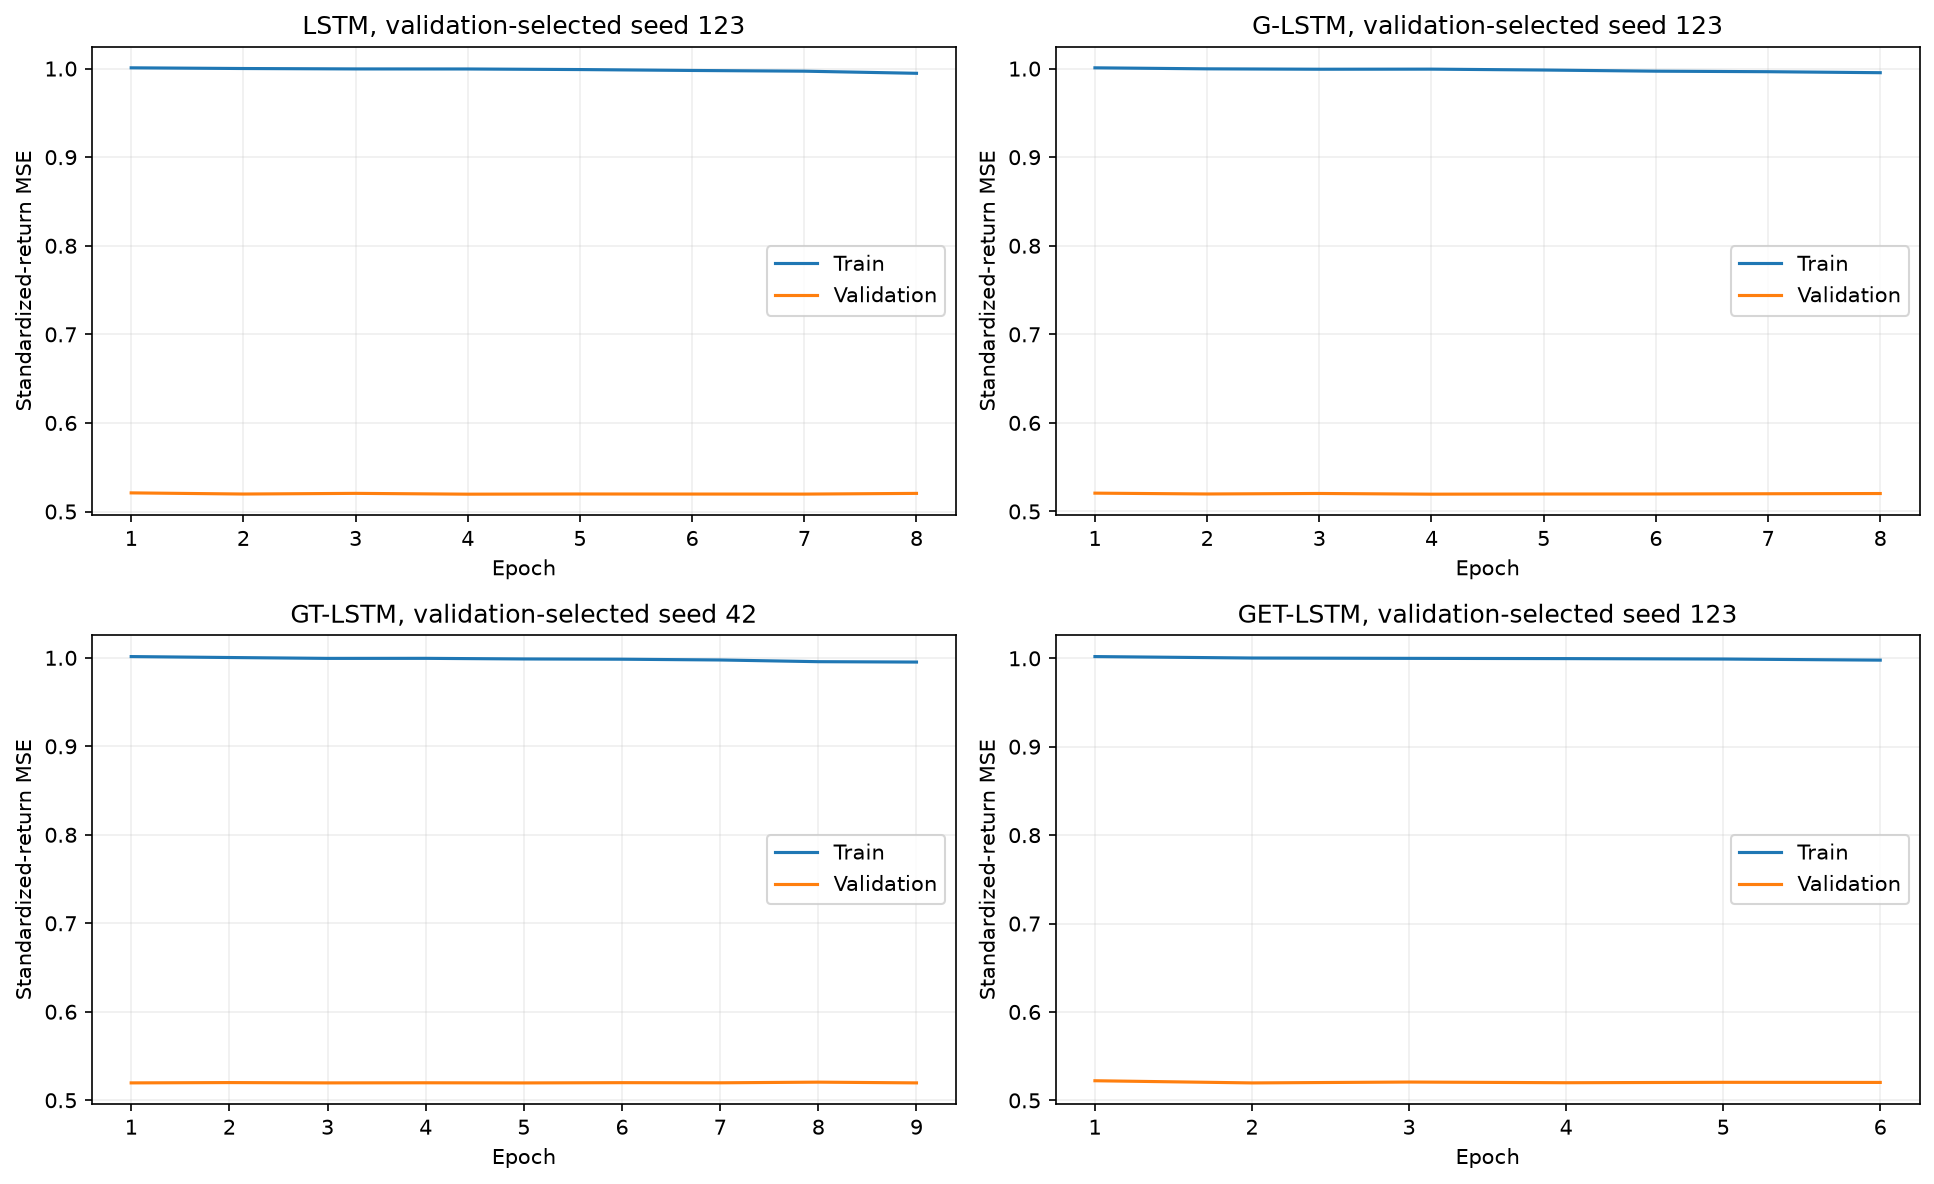

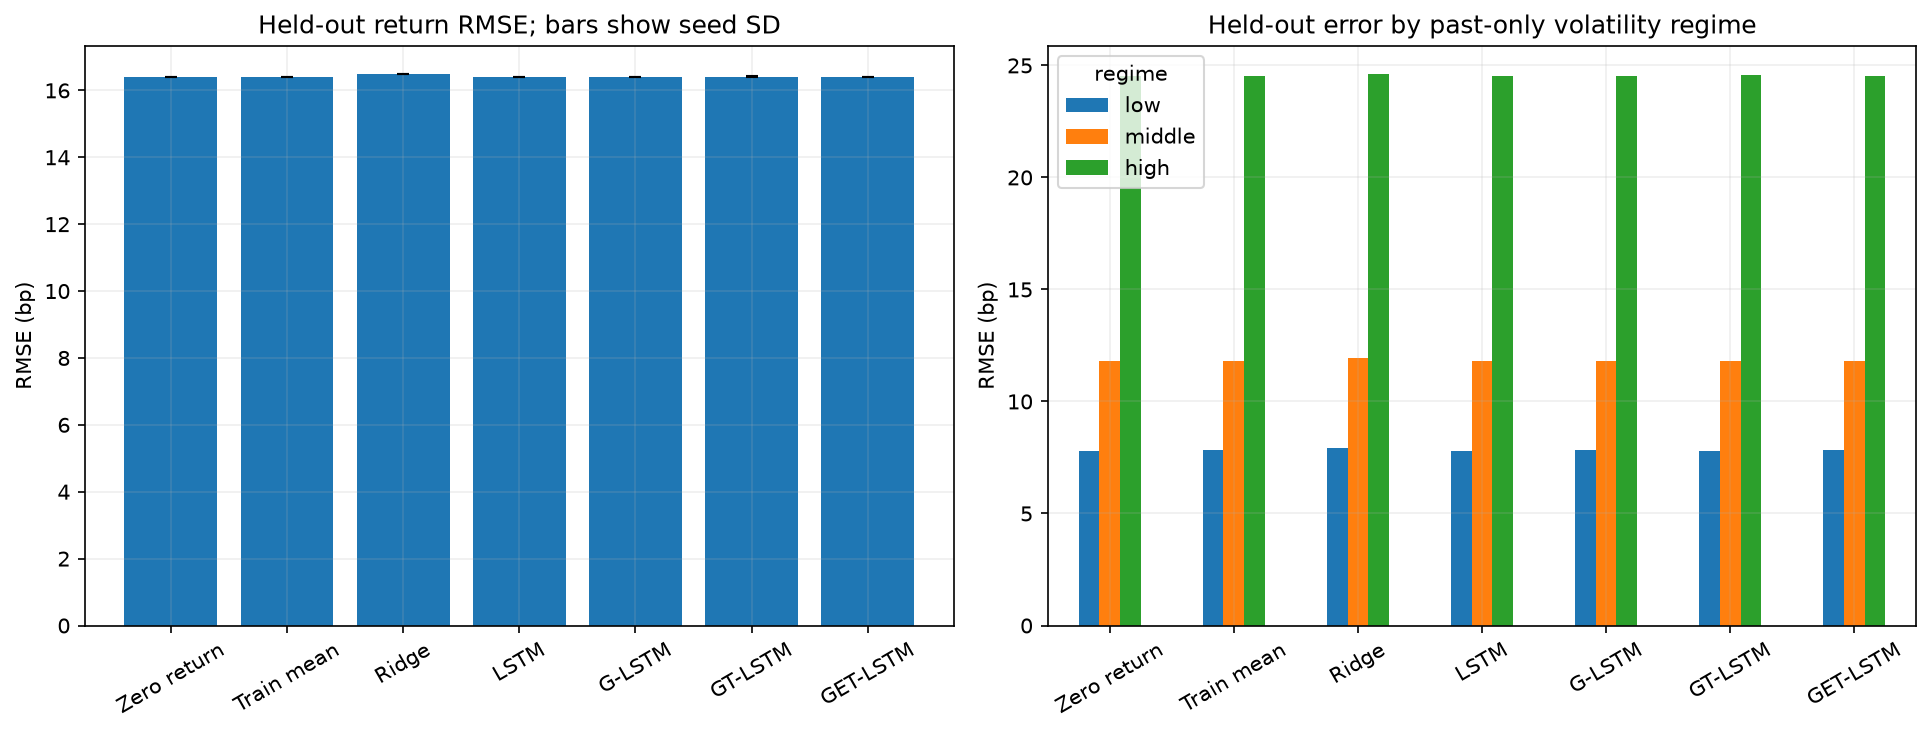

In [11]:
history = pd.DataFrame(training_rows)
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for axis, name in zip(ax.flat, feature_sets):
    seed = selected_seeds[name]
    h = history[(history.model == name) & (history.seed == seed)]
    axis.plot(h.epoch, h.train_mse_scaled, label="Train")
    axis.plot(h.epoch, h.validation_mse_scaled, label="Validation")
    axis.set(title=f"{name}, validation-selected seed {seed}", xlabel="Epoch", ylabel="Standardized-return MSE")
    axis.legend()
save_figure(fig, "02_training_losses.png")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
order = list(summary.index)
ax[0].bar(range(len(order)), summary.rmse_bps_mean,
          yerr=summary.rmse_bps_std.fillna(0), capsize=3)
ax[0].set_xticks(range(len(order)), order, rotation=30)
ax[0].set(title="Held-out return RMSE; bars show seed SD", ylabel="RMSE (bp)")
regime_mean = regime_metrics.groupby(["model", "regime"]).rmse_bps.mean().unstack()
regime_mean.reindex(order)[["low", "middle", "high"]].plot.bar(ax=ax[1])
ax[1].set(title="Held-out error by past-only volatility regime", ylabel="RMSE (bp)", xlabel="")
ax[1].tick_params(axis="x", rotation=30)
save_figure(fig, "03_test_metrics.png")

## 11. Observed/predicted prices, returns, and successes/failures

Each predicted close uses the **observed current close** and one predicted return. This is one-step forecasting with new observed inputs at every origin, not a recursively generated price path. Qualitative windows are chosen after evaluation using the explicitly saved example rule.

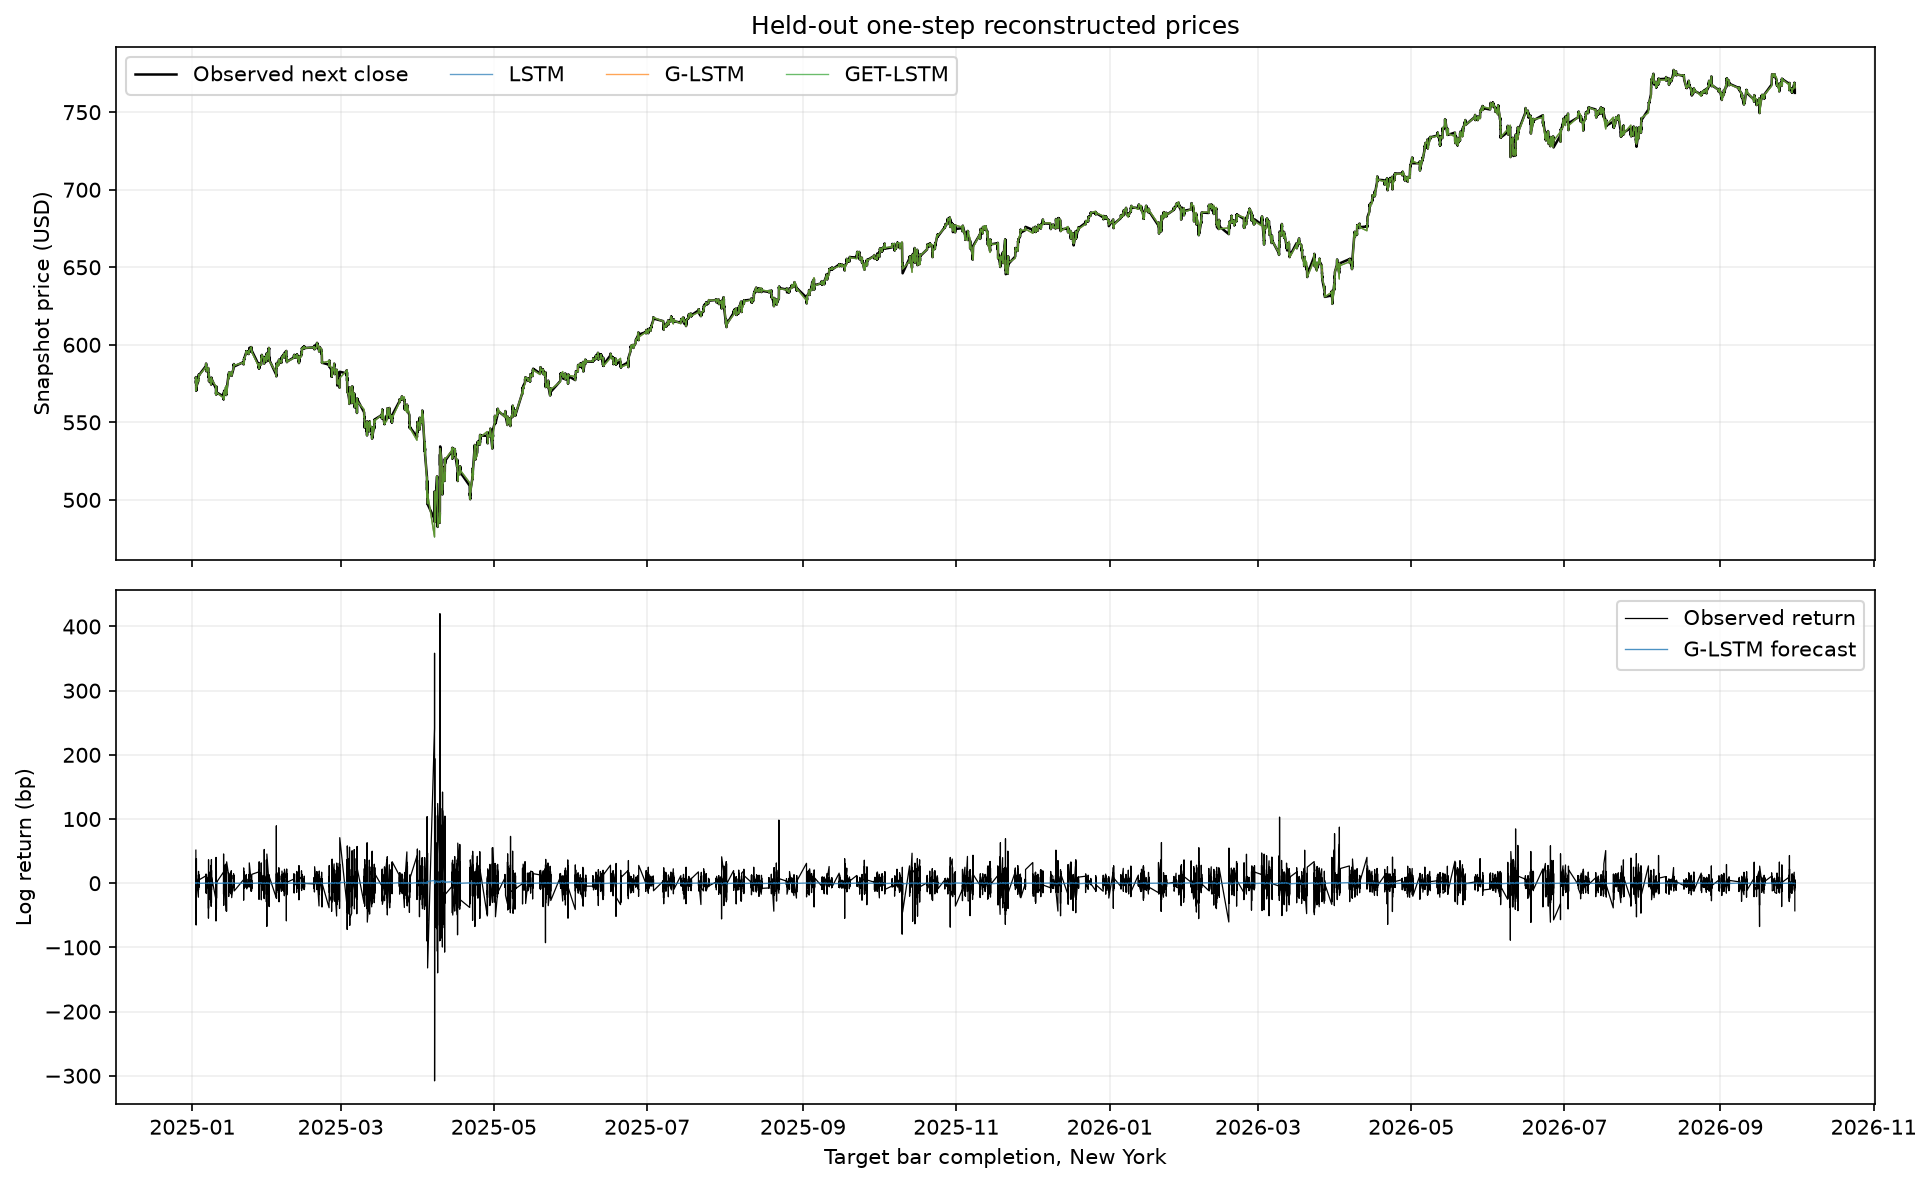

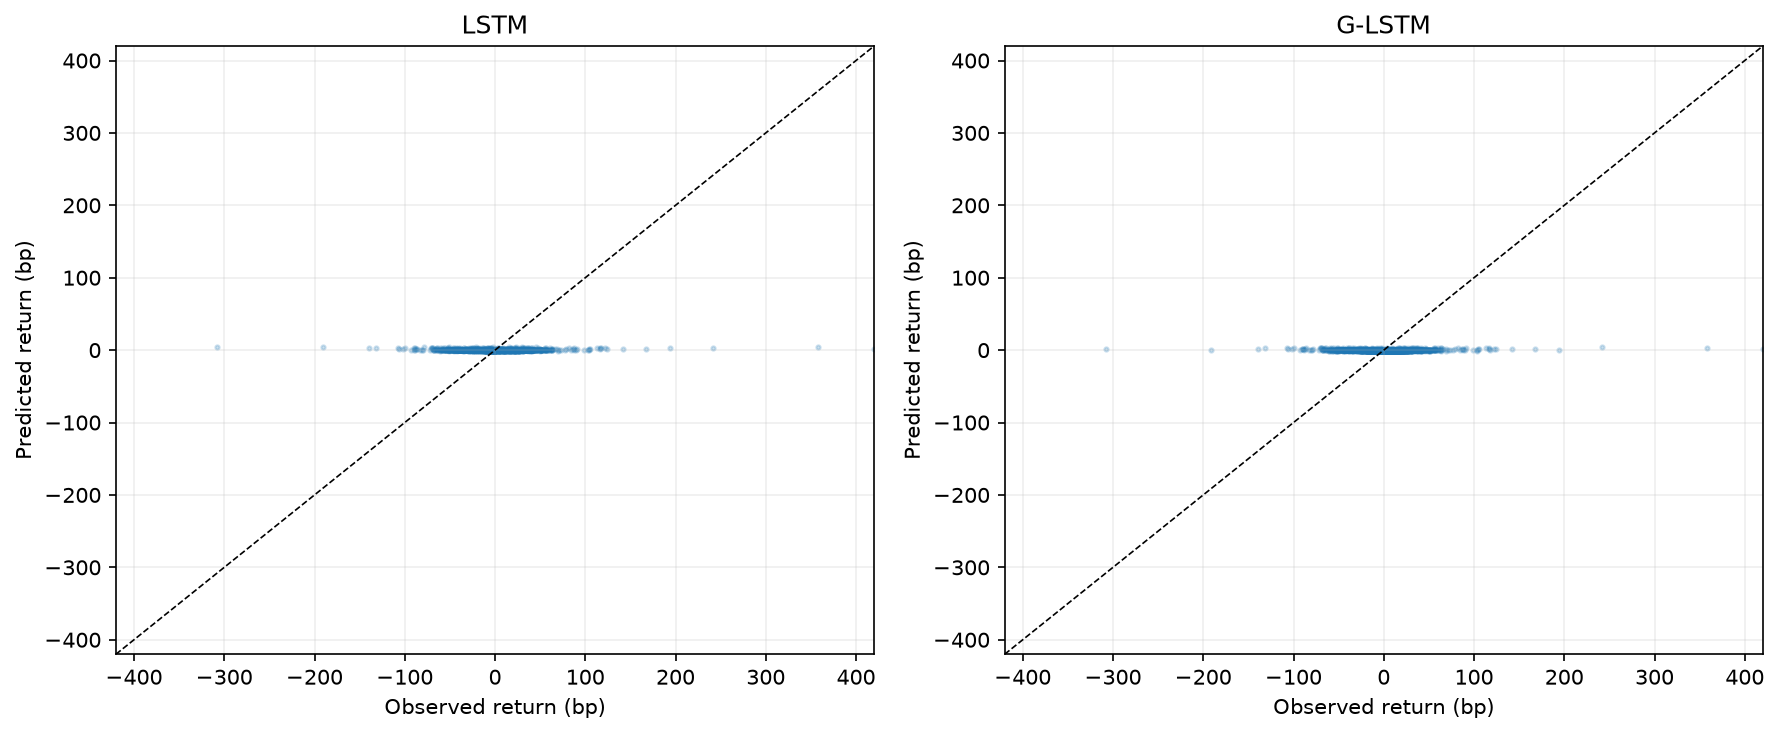

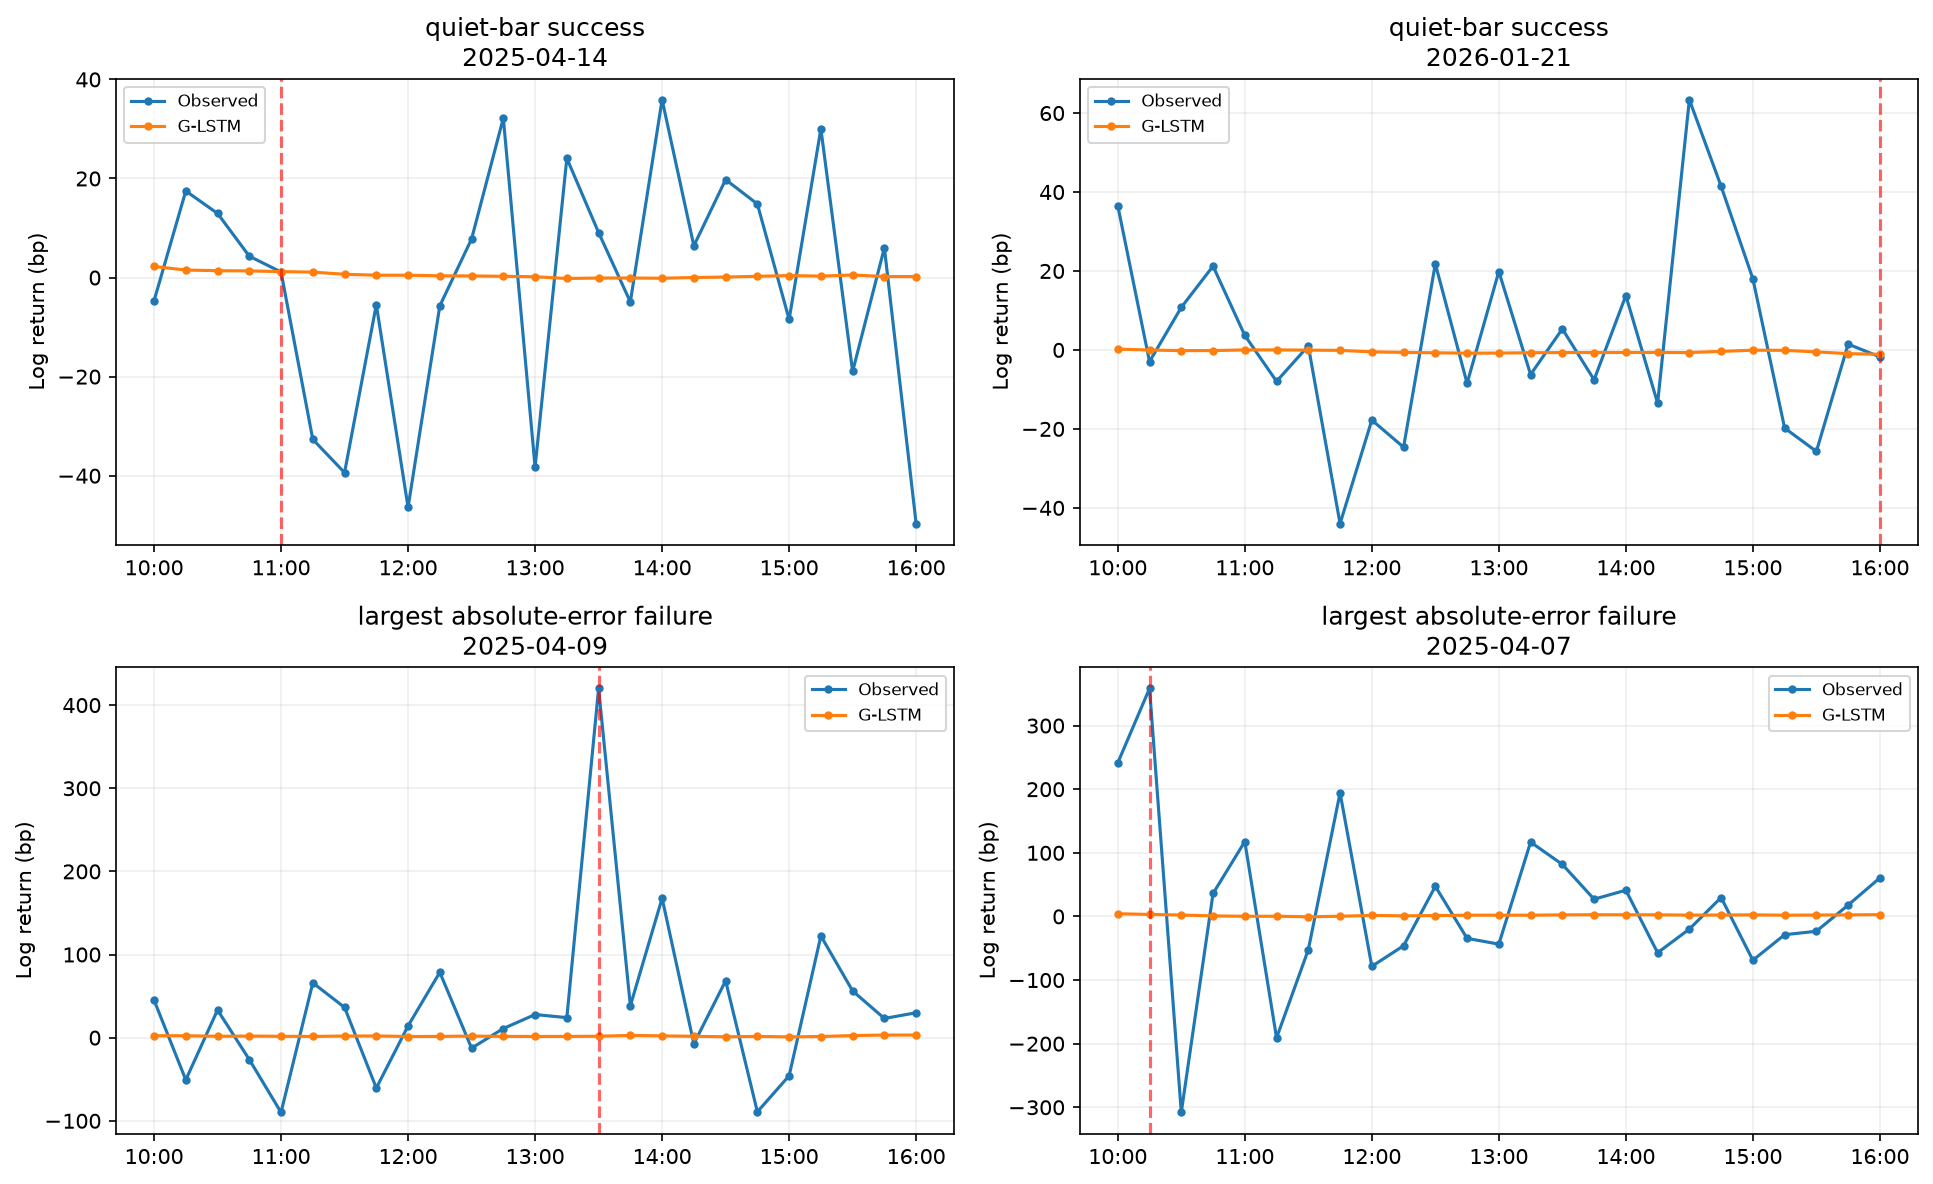

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
base_test = samples.iloc[partitions["test"]]
x_time = base_test.target_available_utc.dt.tz_convert("America/New_York")
ax[0].plot(x_time, base_test.target_close, color="black", linewidth=1.2, label="Observed next close")
for name in ["LSTM", "G-LSTM", "GET-LSTM"]:
    p = representative[representative.model == name].sort_values("sample_id")
    ax[0].plot(x_time, p.predicted_close, linewidth=0.65, alpha=.7, label=name)
ax[0].set(title="Held-out one-step reconstructed prices", ylabel="Snapshot price (USD)")
ax[0].legend(ncol=4)
ax[1].plot(x_time, base_test.target_return * 10000, linewidth=.6, color="black", label="Observed return")
p = representative[representative.model == "G-LSTM"].sort_values("sample_id")
ax[1].plot(x_time, p.predicted_return * 10000, linewidth=.65, alpha=.8, label="G-LSTM forecast")
ax[1].set(ylabel="Log return (bp)", xlabel="Target bar completion, New York")
ax[1].legend()
save_figure(fig, "04_test_prices_and_returns.png")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for axis, name in zip(ax, ["LSTM", "G-LSTM"]):
    p = representative[representative.model == name]
    axis.scatter(p.target_return * 10000, p.predicted_return * 10000, s=4, alpha=.22)
    limit = max(abs(p.target_return.min()), abs(p.target_return.max())) * 10000
    axis.plot([-limit, limit], [-limit, limit], color="black", linestyle="--", linewidth=.8)
    axis.set(xlim=(-limit, limit), ylim=(-limit, limit), title=name,
             xlabel="Observed return (bp)", ylabel="Predicted return (bp)")
save_figure(fig, "05_return_scatter.png")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for axis, example in zip(ax.flat, examples.itertuples()):
    sample = focal[focal.session == example.session].sort_values("sample_id")
    hours = sample.target_ts_utc.dt.tz_convert("America/New_York") + step
    axis.plot(hours, sample.target_return * 10000, marker=".", label="Observed")
    axis.plot(hours, sample.predicted_return * 10000, marker=".", label="G-LSTM")
    marked = example.target_ts_utc.tz_convert("America/New_York") + step
    axis.axvline(marked, color="red", linestyle="--", alpha=.6)
    axis.set(title=f"{example.example_type}\n{example.session}", ylabel="Log return (bp)")
    axis.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%H:%M", tz="America/New_York"))
    axis.legend(fontsize=8)
save_figure(fig, "06_successes_and_failures.png")

## 12. Save reproducibility metadata and interpret the baseline

The frozen neural weights use 2016–2022 labels with 2023–2024 validation stopping. GARCH parameters continue to update from prior observed data during the test period, as declared before evaluation; neural weights and scalers do not. Three-seed results describe initialization variability, not an exhaustive optimization study.

See `check-in-2.md` for the measured results, selected examples, failure analysis, and Check-in 3 priorities. The report is written after this notebook runs; its tables trace to `data/results/`.

References: [arch volatility models](https://arch.readthedocs.io/en/stable/univariate/univariate_volatility_modeling.html), [PyTorch LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).

In [5]:
versions = {name: metadata.version(name) for name in
            ["numpy", "pandas", "torch", "arch", "matplotlib", "statsmodels", "scikit-learn",
             "pyarrow", "pandas-market-calendars", "nbformat", "nbclient", "ipykernel"]}
manifest = {"python": platform.python_version(), "platform": platform.platform(),
            "versions": versions, "config": CONFIG, "source_sha256": source_hash,
            "feature_sets": feature_sets, "representative_seeds": selected_seeds,
            "raw_adjustment_and_feed_confirmed": False,
            "selection": "fixed model design; epoch and representative seed chosen using validation only"}
(DATA / "results" / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Completed. Data and tables:", DATA)
print("Figures:", FIGURES)
print("Source dataset SHA-256:", source_hash)
display(summary)
# Validate matched sample counts and finite predictions across all comparisons.
assert test.groupby(["model", "seed"]).size().nunique() == 1
assert np.isfinite(test[["target_return", "predicted_return", "predicted_close"]].to_numpy()).all()
assert set(test.model) == set(feature_sets) | {"Zero return", "Train mean", "Ridge"}
print("Passed timestamp, finite-value, matched-sample, and split checks.")

Completed. Data and tables: /Users/yinhengyuan/Documents/ggt/DSAN/6600/6600-project/data
Figures: /Users/yinhengyuan/Documents/ggt/DSAN/6600/6600-project/visualizations
Source dataset SHA-256: bda19e9f8a784ee50d20fe7dc50826d5fce0fddea97b205257a569312aa42b67


,runs,n,rmse_bps_mean,rmse_bps_std,mae_bps_mean,r2_vs_zero_mean,direction_accuracy_mean,price_rmse_usd_mean,price_mae_usd_mean
model,,,,,,,,,
Zero return,1,10889,16.405443,NaN,9.747769,0.000000,0.000000,0.973881,0.618347
Train mean,1,10889,16.405275,NaN,9.747162,0.000021,0.511508,0.973874,0.618308
Ridge,1,10889,16.503145,NaN,9.880923,-0.011946,0.498752,0.981065,0.626838
LSTM,3,10889,16.405509,0.002463,9.747713,-0.000008,0.510830,0.974005,0.618313
G-LSTM,3,10889,16.405379,0.004396,9.750056,0.000008,0.503312,0.974039,0.618484
GT-LSTM,3,10889,16.410023,0.006018,9.754483,-0.000558,0.495979,0.974194,0.618759
GET-LSTM,3,10889,16.406463,0.001556,9.751923,-0.000124,0.498044,0.974027,0.618611


Passed timestamp, finite-value, matched-sample, and split checks.
